In [2]:
from Bio import SeqIO
from Bio import pairwise2
from Bio.pairwise2 import align, format_alignment
from collections import Counter
from Bio.Seq import Seq
from Bio.SeqUtils import gc_fraction, molecular_weight as mw, MeltingTemp as mt
from Levenshtein import hamming, distance
import matplotlib.pyplot as plt

c:\Users\Zhvn\AppData\Local\Programs\Python\Python310\lib\site-packages\Bio\pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


Length of Homo Sapiens Sequence:  1430
Start codon position in Homo Sapiens Sequence:  45
Selected inverse Sequence:  AACTACATATACGTACGGACGTTCGGATCA
Nucleotide counts in Homo Sapiens Sequence:  Counter({'C': 449, 'A': 352, 'G': 339, 'T': 290})
GC content of Homo Sapiens Sequence: 55.10% and AT content of Homo Sapiens Sequence: 44.90%
Melting temperature of Homo Sapiens Sequence:  4436.0
Translate sequence of Homo Sapiens Sequence:  TRLAGQAVPGVWLRCYQLPFCWSWQCPWLLKITPRVMAPVGYGSGKTHRVVSASSAGRLHSMGPGPGWSASRSSRTTATGTTHVEAAC*IHDGCSLLLTASSAKIMCMTGDWFSEQRKLHMGTINQ*RRLCKRDMWRKSSFMKNTTLRQREMTLPSWRSPLPFRVGASLGRAACPTLRQASPEAPRAAGWPAGDI*KRKPPGHHLY*WRHVWISSTWTCVTRPSGTMGAFSQPMCARGIL*ARSTPARETAAGLSCAKTARKAPMWSWESQAGG*AVPVPSAPESTRPPGPI*TGSPPRLVLTLCV*FNRPPLHLPPLDRPRFDPPSPTLSLLTFLGISNRPLDHFHPDHRQPSPDPHLHPRPHPHLQPHLYPHPHPHPHLHPHLPQNFPKDFLLPSAYSSS*RS*RGRPIPTERTIMTWRPQSSQN*PRPPDLTWFSTDPVSPSLLRKRKDEINK*TYIYRYTHTHICMYTCIYI
ACTAGGCTTGCAGGCCAGGCAGTGCCAGGAGTATGGTTGAGATGCTACCAACTGCCATTCTGCTGGTCTTGGCAGTGTCCGTGGTTG

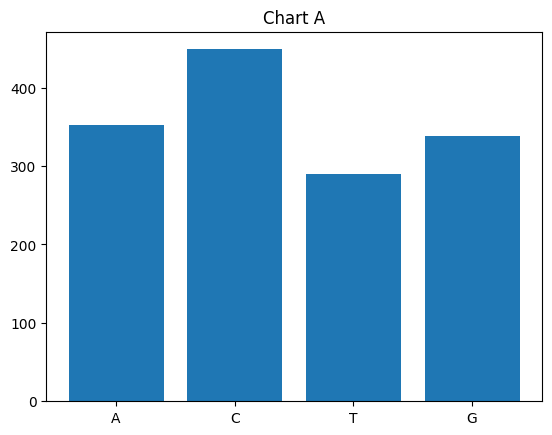

In [24]:
SeqA = SeqIO.read("homoSapiens.gb","genbank").seq

lengthA = len(SeqA)
print("Length of Homo Sapiens Sequence: ", lengthA)

StartA = SeqA.index("TAC")
FirstA = SeqA[:15]
LastA = SeqA[-15:]
InverseA = (FirstA + LastA) [::-1]
print("Start codon position in Homo Sapiens Sequence: ", StartA)
print("Selected inverse Sequence: ", InverseA)

Counter_A = Counter(SeqA)
print("Nucleotide counts in Homo Sapiens Sequence: ", Counter_A)

plt.bar(Counter_A.keys(), Counter_A.values())
plt.title("Chart A")
plt.show

gc_a = gc_fraction(SeqA) * 100
at_a = 100 - gc_a
print(f"GC content of Homo Sapiens Sequence: {gc_a:.2f}% and AT content of Homo Sapiens Sequence: {at_a:.2f}%")

mt_a = mt.Tm_Wallace(SeqA)
mw_a = mw(SeqA)
print("Melting temperature of Homo Sapiens Sequence: ", mt_a)

tc_a = SeqA.transcribe()
tl_a = tc_a.translate()
print("Translate sequence of Homo Sapiens Sequence: ", tl_a)

Global_alignment = pairwise2.align.globalxx(SeqA, "ATGC")
for alignment in Global_alignment:
    print(format_alignment(*alignment))